# Milestone 9 — Quantitative Results Revalidation
**Target:** MaNGA 8138-12704 · **DAPTYPE:** HYB10-MILESHC-MASTARSSP

## Purpose
This notebook re-computes the main Milestone 5–6 quantities after Milestone 8 validation. It uses one representative measurement per unique stellar-continuum bin (`BINID[1]`), excludes pixels outside that footprint, inspects DAP masks and IVAR, and compares alternative weighting choices.

**Important:** This is a revalidation, not a guarantee that previous values are correct. Results are first-order projected measurements. They are not deprojected circular speeds, black-hole masses, or evidence by themselves for a binary SMBH.

Run from the project root or edit `PROJECT_ROOT` below. Required inputs: MAPS FITS and the previously created processed NPZ (for comparison only).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 220, "font.size": 10})

ImportError: DLL load failed while importing groupby: An Application Control policy has blocked this file.

In [ ]:
PROJECT_ROOT = Path(r"D:\KS\manga-stellar-kinematics")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
REPORT_DIR = OUTPUT_DIR / "reports"
for p in [OUTPUT_DIR, FIGURES_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

MAPS_PATH = RAW_DIR / "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz"
if not MAPS_PATH.exists():
    raise FileNotFoundError(f"MAPS file not found: {MAPS_PATH}")
print("Using:", MAPS_PATH)

Using: D:\KS\manga-stellar-kinematics\data\raw\manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz


In [ ]:
maps = fits.open(MAPS_PATH, memmap=True)
available = {h.name.upper() for h in maps}
required = [
    "BINID", "STELLAR_VEL", "STELLAR_VEL_IVAR", "STELLAR_VEL_MASK",
    "STELLAR_SIGMA", "STELLAR_SIGMA_IVAR", "STELLAR_SIGMA_MASK",
    "STELLAR_SIGMACORR", "BIN_LWSKYCOO", "BIN_LWELLCOO", "BIN_MFLUX"
]
missing = [x for x in required if x not in available]
if missing:
    raise KeyError(f"Missing required MAPS extensions: {missing}")

binid = np.asarray(maps["BINID"].data)
vel = np.asarray(maps["STELLAR_VEL"].data, dtype=float)
vel_ivar = np.asarray(maps["STELLAR_VEL_IVAR"].data, dtype=float)
vel_mask = np.asarray(maps["STELLAR_VEL_MASK"].data, dtype=np.uint32)
sig_raw = np.asarray(maps["STELLAR_SIGMA"].data, dtype=float)
sig_ivar = np.asarray(maps["STELLAR_SIGMA_IVAR"].data, dtype=float)
sig_mask = np.asarray(maps["STELLAR_SIGMA_MASK"].data, dtype=np.uint32)
sig_inst = np.asarray(maps["STELLAR_SIGMACORR"].data[0], dtype=float)
sky = np.asarray(maps["BIN_LWSKYCOO"].data, dtype=float)
ell = np.asarray(maps["BIN_LWELLCOO"].data, dtype=float)
bin_mflux = np.asarray(maps["BIN_MFLUX"].data, dtype=float)

print("MAPS BINID channel labels:", [maps["BINID"].header.get(f"C{i}") for i in range(1, 6)])
print("Array shapes:", binid.shape, vel.shape, sky.shape, ell.shape, bin_mflux.shape)

MAPS BINID channel labels: ['Binned spectra', 'Stellar continua', 'Em. line moments', 'Em. line models', 'Spectral indices']
Array shapes: (5, 72, 72) (72, 72) (2, 72, 72) (4, 72, 72) (72, 72)


## 1. Build the validated stellar-bin sample

The header labels `C2 = Stellar continua`; NumPy index is therefore `BINID[1]`. The Milestone 8 audit found 2,704 covered spaxels and 2,194 unique IDs, including 2,072 singleton bins. We extract one measurement per unique bin and separately calculate the number of spaxels represented by each bin.

In [ ]:
stellar_binid = binid[1]
covered = stellar_binid >= 0
flat_ids = stellar_binid[covered]
unique_ids, first_idx = np.unique(flat_ids, return_index=True)
covered_flat_indices = np.flatnonzero(covered.ravel())
rep_flat = covered_flat_indices[first_idx]
rep_y, rep_x = np.unravel_index(rep_flat, vel.shape)

# Number of spaxels represented by each stellar bin
ids_all, counts = np.unique(flat_ids, return_counts=True)
count_lookup = dict(zip(ids_all.tolist(), counts.tolist()))
bin_area = np.array([count_lookup[i] for i in unique_ids], dtype=float)

def at_rep(arr):
    return np.asarray(arr)[rep_y, rep_x]

v = at_rep(vel)
v_ivar = at_rep(vel_ivar)
v_mask_b = at_rep(vel_mask)
sraw = at_rep(sig_raw)
sinst = at_rep(sig_inst)
s_ivar = at_rep(sig_ivar)
s_mask_b = at_rep(sig_mask)
x = at_rep(sky[0])
y = at_rep(sky[1])
r_re = at_rep(ell[1])
r_arcsec = at_rep(ell[0])
theta = at_rep(ell[3])
f_bin = at_rep(bin_mflux)

print("Covered spaxels:", int(covered.sum()))
print("Unique stellar bins:", len(unique_ids))
print("Singleton bins:", int((bin_area == 1).sum()))
print("Multi-spaxel bins:", int((bin_area > 1).sum()))
print("Median bin area:", float(np.median(bin_area)))

Covered spaxels: 2704
Unique stellar bins: 2194
Singleton bins: 2072
Multi-spaxel bins: 122
Median bin area: 1.0


## 2. Apply the validated footprint and DAP quality masks

Milestone 8 found that mask value `2**30 + 2**4` occurs outside the stellar BINID footprint. We still apply the mask bits to representative bin measurements and report their counts. A bin is retained only when it belongs to the stellar footprint, has finite measurements and positive IVAR, and has no excluded DAP flags.

In [ ]:
DAP_BITS = {
    "NOCOV": 0, "LOWCOV": 1, "DEADFIBER": 2, "FORESTAR": 3,
    "NOVALUE": 4, "UNRELIABLE": 5, "MATHERROR": 6,
    "FITFAILED": 7, "NEARBOUND": 8, "NOCORRECTION": 9, "DONOTUSE": 30
}
EXCLUDED = list(DAP_BITS)

def flagged(mask, names=EXCLUDED):
    bits = 0
    for name in names:
        bits |= (1 << DAP_BITS[name])
    return (mask.astype(np.uint64) & np.uint64(bits)) != 0

sig2 = sraw**2 - sinst**2
sig = np.full_like(sraw, np.nan)
sig_physical = np.isfinite(sig2) & (sig2 >= 0) & np.isfinite(sinst) & (sinst >= 0)
sig[sig_physical] = np.sqrt(sig2[sig_physical])

v_ok = (
    ~flagged(v_mask_b) & np.isfinite(v) &
    np.isfinite(v_ivar) & (v_ivar > 0) &
    np.isfinite(x) & np.isfinite(y) &
    np.isfinite(r_re) & (r_re >= 0)
)
s_ok = (
    ~flagged(s_mask_b) & sig_physical & np.isfinite(sig) &
    np.isfinite(s_ivar) & (s_ivar > 0) &
    np.isfinite(x) & np.isfinite(y) &
    np.isfinite(r_re) & (r_re >= 0)
)
joint = v_ok & s_ok & np.isfinite(f_bin) & (f_bin > 0)

print("Valid velocity bins:", int(v_ok.sum()))
print("Valid corrected-sigma bins:", int(s_ok.sum()))
print("Joint valid bins with positive BIN_MFLUX:", int(joint.sum()))
print("Bins with invalid sigma correction:", int((~sig_physical).sum()))
print("Velocity mask values at representatives:", np.unique(v_mask_b, return_counts=True))
print("Sigma mask values at representatives:", np.unique(s_mask_b, return_counts=True))

Valid velocity bins: 2194
Valid corrected-sigma bins: 2194
Joint valid bins with positive BIN_MFLUX: 2194
Bins with invalid sigma correction: 0
Velocity mask values at representatives: (array([0], dtype=uint32), array([2194]))
Sigma mask values at representatives: (array([0], dtype=uint32), array([2194]))


## 3. Systemic-velocity treatment

The previous notebook used the median of all bin velocities as a residual systemic offset. Because a rotating galaxy has approaching and receding sides, that median is not necessarily the systemic velocity. Here we report it only as a descriptive median, and estimate the intercept of a weighted two-dimensional velocity-plane fit separately. Neither is an absolute heliocentric systemic velocity.

In [ ]:
def weighted_plane(xv, yv, zv, ivar):
    good = (
        np.isfinite(xv) & np.isfinite(yv) & np.isfinite(zv) &
        np.isfinite(ivar) & (ivar > 0)
    )
    A = np.column_stack([xv[good], yv[good], np.ones(good.sum())])
    w = ivar[good] / np.nanmedian(ivar[good])
    Aw = A * np.sqrt(w)[:, None]
    zw = zv[good] * np.sqrt(w)
    coef, *_ = np.linalg.lstsq(Aw, zw, rcond=None)
    return coef, good

coef, plane_good = weighted_plane(x[v_ok], y[v_ok], v[v_ok], v_ivar[v_ok])
a, b, c = coef
grad = np.hypot(a, b)
pa_receding = np.degrees(np.arctan2(a, b)) % 360
pa_axis = pa_receding % 180
median_velocity = float(np.nanmedian(v[v_ok]))
print(f"Descriptive median bin velocity: {median_velocity:.3f} km/s")
print(f"Weighted plane intercept at x=y=0: {c:.3f} km/s")
print(f"Gradient east: {a:.4f} km/s/arcsec")
print(f"Gradient north: {b:.4f} km/s/arcsec")
print(f"Gradient amplitude: {grad:.4f} km/s/arcsec")
print(f"First-order kinematic PA axis: {pa_axis:.3f} deg (N through E, modulo 180)")

Descriptive median bin velocity: 33.644 km/s
Weighted plane intercept at x=y=0: 23.251 km/s
Gradient east: 4.4576 km/s/arcsec
Gradient north: -19.7806 km/s/arcsec
Gradient amplitude: 20.2767 km/s/arcsec
First-order kinematic PA axis: 167.300 deg (N through E, modulo 180)


## 4. Compare weighting choices for the velocity-plane fit

The primary fit uses inverse-variance weighting once per unique bin. A second diagnostic fit weights each bin by its spaxel count as well. These are sensitivity checks, not interchangeable definitions of the optimal likelihood. The bin centroid coordinates are taken from the DAP BIN coordinate maps.

In [ ]:
# Fit A: inverse-variance weighted once per unique bin (primary)
coef_ivar, _ = weighted_plane(x[v_ok], y[v_ok], v[v_ok], v_ivar[v_ok])

# Fit B: inverse-variance multiplied by represented spaxel count (sensitivity only)
good = v_ok & (bin_area > 0)
A2 = np.column_stack([x[good], y[good], np.ones(good.sum())])
w2 = (v_ivar[good] / np.nanmedian(v_ivar[good])) * bin_area[good]
coef_area, *_ = np.linalg.lstsq(A2 * np.sqrt(w2)[:, None], v[good] * np.sqrt(w2), rcond=None)

def summarize_plane(label, cc):
    aa, bb, intercept = cc
    return {
        "fit": label,
        "intercept_km_s": intercept,
        "gradient_km_s_arcsec": np.hypot(aa, bb),
        "PA_axis_deg": np.degrees(np.arctan2(aa, bb)) % 180
    }

plane_comparison = pd.DataFrame([
    summarize_plane("inverse_variance", coef_ivar),
    summarize_plane("inverse_variance_times_bin_area", coef_area)
])
display(plane_comparison)

,fit,intercept_km_s,gradient_km_s_arcsec,PA_axis_deg
0,inverse_variance,23.251465,20.276669,167.300313
1,inverse_variance_times_bin_area,23.409395,19.950936,166.491410


## 5. Rotation amplitude proxy and radial profiles

We retain the 5th–95th percentile half-range as a descriptive projected velocity-amplitude proxy. It is not a circular velocity. Radial profiles use the DAP elliptical radius in units of effective radius (`R/Re`).

5th–95th percentile residual range: -204.20 to 209.47 km/s
Projected rotation amplitude proxy: 206.83 km/s


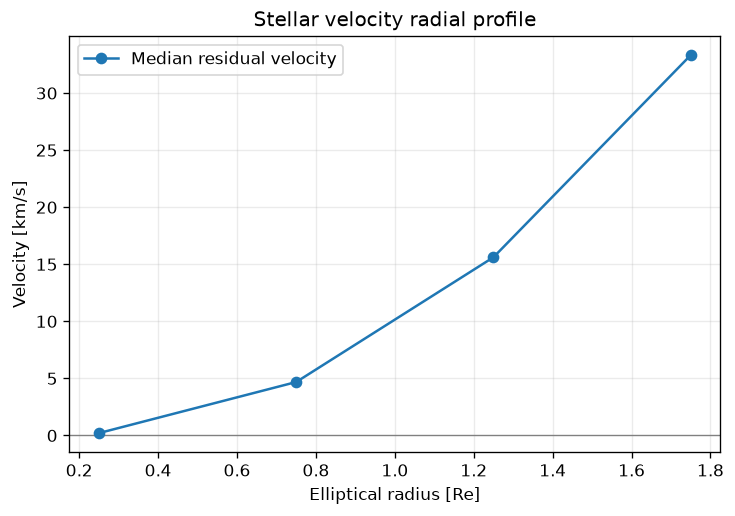

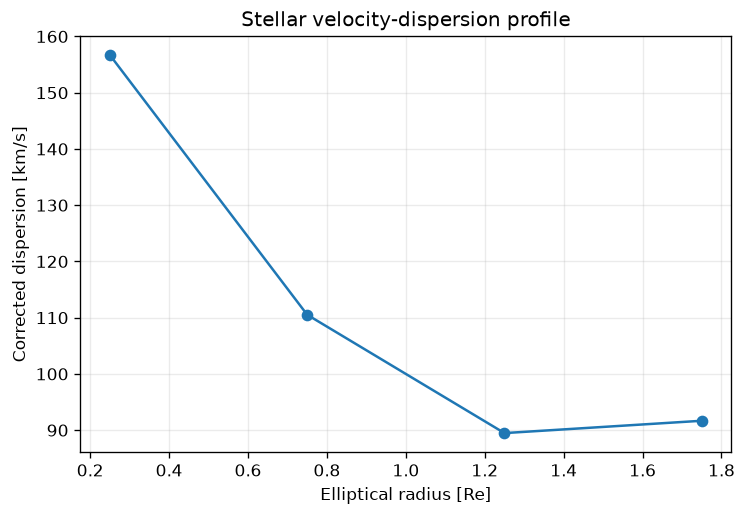

In [ ]:
v_model = a*x + b*y + c
v_resid = v - c
v_low, v_high = np.nanpercentile(v_resid[v_ok], [5, 95])
vrot_proxy = 0.5 * (v_high - v_low)
print(f"5th–95th percentile residual range: {v_low:.2f} to {v_high:.2f} km/s")
print(f"Projected rotation amplitude proxy: {vrot_proxy:.2f} km/s")

radial_edges = np.arange(0, np.ceil(np.nanmax(r_re[joint]) * 2) / 2 + 0.5, 0.5)
if len(radial_edges) < 3:
    radial_edges = np.linspace(0, max(float(np.nanmax(r_re[joint])), 1), 4)
radial_centers = (radial_edges[:-1] + radial_edges[1:]) / 2
v_profile = np.full(len(radial_centers), np.nan)
s_profile = np.full(len(radial_centers), np.nan)
n_profile = np.zeros(len(radial_centers), dtype=int)
for i, (lo, hi) in enumerate(zip(radial_edges[:-1], radial_edges[1:])):
    m = joint & (r_re >= lo) & (r_re < hi)
    n_profile[i] = m.sum()
    if m.any():
        v_profile[i] = np.nanmedian(v_resid[m])
        s_profile[i] = np.nanmedian(sig[m])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(radial_centers, v_profile, fmt="o-", label="Median residual velocity")
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xlabel="Elliptical radius [Re]", ylabel="Velocity [km/s]", title="Stellar velocity radial profile")
ax.grid(alpha=.25); ax.legend(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(radial_centers, s_profile, "o-")
ax.set(xlabel="Elliptical radius [Re]", ylabel="Corrected dispersion [km/s]", title="Stellar velocity-dispersion profile")
ax.grid(alpha=.25); plt.show()

## 6. Recompute λR with explicit bin-area sensitivity

For a binned map, a bin-level sum should represent the luminosity contribution of the whole bin, not automatically one identical contribution per bin. `BIN_MFLUX` is a mean flux-like quantity; this notebook therefore compares:
- **Uncorrected bin weighting:** `BIN_MFLUX` per bin (the previous notebook's approach).
- **Area-scaled weighting:** `BIN_MFLUX × number of spaxels in the bin` (a sensitivity estimate for the integrated contribution).

This is an approximation. The exact interpretation of `BIN_MFLUX` and the correct luminosity/area treatment must be checked against the DAP data model before treating either λR value as definitive. Radius and velocity are represented at the bin location.

In [ ]:
def lambda_r(radius, flux_weight, velocity, dispersion, aperture, valid_sample):
    use = (
        valid_sample &
        np.isfinite(radius) & (radius <= aperture) &
        np.isfinite(flux_weight) & (flux_weight > 0) &
        np.isfinite(velocity) & np.isfinite(dispersion) & (dispersion >= 0)
    )
    if not use.any():
        return np.nan, 0
    numerator = np.sum(flux_weight[use] * radius[use] * np.abs(velocity[use]))
    denominator = np.sum(
        flux_weight[use] * radius[use] *
        np.sqrt(velocity[use]**2 + dispersion[use]**2)
    )
    return (numerator / denominator if denominator > 0 else np.nan), int(use.sum())

flux_bin_area = f_bin * bin_area
lambda_rows = []
for aperture in [1.0, 2.0]:
    l0, n0 = lambda_r(r_re, f_bin, v_resid, sig, aperture, joint)
    l1, n1 = lambda_r(r_re, flux_bin_area, v_resid, sig, aperture, joint)
    lambda_rows.extend([
        {"aperture_Re": aperture, "weighting": "BIN_MFLUX_per_bin", "lambda_R": l0, "n_bins": n0},
        {"aperture_Re": aperture, "weighting": "BIN_MFLUX_times_bin_area", "lambda_R": l1, "n_bins": n1}
    ])
lambda_comparison = pd.DataFrame(lambda_rows)
display(lambda_comparison)

,aperture_Re,weighting,lambda_R,n_bins
0,1.0,BIN_MFLUX_per_bin,0.646453,1024
1,1.0,BIN_MFLUX_times_bin_area,0.646453,1024
2,2.0,BIN_MFLUX_per_bin,0.715884,2194
3,2.0,BIN_MFLUX_times_bin_area,0.700203,2194


## 7. Compare with previously reported values

The old summary is hard-coded below for transparent comparison. Differences are not automatically errors: the revised systemic-velocity treatment and mask/weighting logic have changed. Interpret the comparison alongside the diagnostic tables and figures.

In [ ]:
previous = {
    "unique_bins": 2194,
    "residual_systemic_velocity_km_s": 33.6441,
    "robust_velocity_scatter_km_s": 190.3056,
    "first_order_PA_deg": 167.3003,
    "gradient_km_s_arcsec": 20.2767,
    "projected_rotation_proxy_km_s": 206.8342,
    "lambda_R_1Re": 0.64621,
    "lambda_R_2Re": 0.71560
}
print("Previous reported values:")
for k, value in previous.items():
    print(f"{k}: {value}")
print("\nRevalidated values:")
print("Unique bins:", len(unique_ids))
print("Median velocity:", median_velocity)
print("Plane intercept:", c)
print("PA:", pa_axis)
print("Gradient:", grad)
print("Projected rotation proxy:", vrot_proxy)
display(lambda_comparison)

Previous reported values:
unique_bins: 2194
residual_systemic_velocity_km_s: 33.6441
robust_velocity_scatter_km_s: 190.3056
first_order_PA_deg: 167.3003
gradient_km_s_arcsec: 20.2767
projected_rotation_proxy_km_s: 206.8342
lambda_R_1Re: 0.64621
lambda_R_2Re: 0.7156

Revalidated values:
Unique bins: 2194
Median velocity: 33.64405632019043
Plane intercept: 23.25146485145557
PA: 167.30031298907772
Gradient: 20.276669374368016
Projected rotation proxy: 206.83420333862307


,aperture_Re,weighting,lambda_R,n_bins
0,1.0,BIN_MFLUX_per_bin,0.646453,1024
1,1.0,BIN_MFLUX_times_bin_area,0.646453,1024
2,2.0,BIN_MFLUX_per_bin,0.715884,2194
3,2.0,BIN_MFLUX_times_bin_area,0.700203,2194


## 8. Save the revalidation report and figures

Read the outputs before moving to the next milestone. If the λR weighting choices differ materially, do not select one silently; document the adopted definition and its justification.

In [ ]:
report_lines = [
    "MaNGA Quantitative Kinematic Revalidation",
    "Target: 8138-12704",
    "DAPTYPE: HYB10-MILESHC-MASTARSSP",
    f"Covered spaxels: {int(covered.sum())}",
    f"Unique stellar bins: {len(unique_ids)}",
    f"Singleton bins: {int((bin_area == 1).sum())}",
    f"Multi-spaxel bins: {int((bin_area > 1).sum())}",
    f"Valid velocity bins: {int(v_ok.sum())}",
    f"Valid corrected-sigma bins: {int(s_ok.sum())}",
    f"Joint bins: {int(joint.sum())}",
    f"Descriptive median velocity [km/s]: {median_velocity:.6f}",
    f"Weighted plane intercept [km/s]: {c:.6f}",
    f"First-order PA [deg]: {pa_axis:.6f}",
    f"Velocity gradient [km/s/arcsec]: {grad:.6f}",
    f"Projected rotation amplitude proxy [km/s]: {vrot_proxy:.6f}",
    "",
    "Plane-fit sensitivity:",
    plane_comparison.to_string(index=False),
    "",
    "Lambda_R weighting comparison:",
    lambda_comparison.to_string(index=False),
    "",
    "Caveats: projected quantities only; formal IVAR errors exclude systematic effects;",
    "lambda_R depends on flux definition, spatial sampling, bin representation, geometry and PSF."
]
report_path = REPORT_DIR / "quantitative_kinematic_revalidation.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
lambda_comparison.to_csv(REPORT_DIR / "lambda_R_weighting_comparison.csv", index=False)
plane_comparison.to_csv(REPORT_DIR / "kinematic_plane_weighting_comparison.csv", index=False)
print("Saved:", report_path)
print(report_path.read_text(encoding="utf-8"))

Saved: D:\KS\manga-stellar-kinematics\outputs\reports\quantitative_kinematic_revalidation.txt
MaNGA Quantitative Kinematic Revalidation
Target: 8138-12704
DAPTYPE: HYB10-MILESHC-MASTARSSP
Covered spaxels: 2704
Unique stellar bins: 2194
Singleton bins: 2072
Multi-spaxel bins: 122
Valid velocity bins: 2194
Valid corrected-sigma bins: 2194
Joint bins: 2194
Descriptive median velocity [km/s]: 33.644056
Weighted plane intercept [km/s]: 23.251465
First-order PA [deg]: 167.300313
Velocity gradient [km/s/arcsec]: 20.276669
Projected rotation amplitude proxy [km/s]: 206.834203

Plane-fit sensitivity:
                            fit  intercept_km_s  gradient_km_s_arcsec  PA_axis_deg
               inverse_variance       23.251465             20.276669   167.300313
inverse_variance_times_bin_area       23.409395             19.950936   166.491410

Lambda_R weighting comparison:
 aperture_Re                weighting  lambda_R  n_bins
         1.0        BIN_MFLUX_per_bin  0.646453    1024
        

In [ ]:
maps.close()
print("MAPS FITS closed.")

MAPS FITS closed.
